# Proyecto Final Integrador
## Priorización de clientes para campañas de retención: predicción de abandono (churn) en una telco

**Diplomado en Ciencia de Datos y Análisis Avanzado - UTN.BA - Unidad 9**
**Equipo N.º 41 - Aguilar, Damian; Revelchione, Mateo**

Este notebook genera **todos** los números, tablas y figuras del informe final. Sigue CRISP-DM:

1. Comprensión del negocio: KPI, benchmarks y meta fijada antes de entrenar.
2. Comprensión de los datos: descarga validada, calidad y EDA de las hipótesis.
3. Preparación: limpieza, variables derivadas y pipelines.
4. Modelado: reproducción del baseline de la pre-entrega, CV de 5 folds y regla de selección ex ante.
5. Evaluación en test (una sola vez): benchmarks, intervalos bootstrap, curvas, lift y calibración.
6. Validación temporal: por qué no es posible con estos datos.
7. Interpretabilidad (SHAP).
8. Profundización: ablaciones de hipótesis, auditoría por grupos y modelo sin atributos sensibles.
9. Escenario económico paramétrico.
10. Resumen.

Todas las salidas se guardan en `results/`. Las decisiones están registradas en `data_log.md`.

In [1]:
# Instala dependencias solo si faltan (útil en Google Colab)
import importlib.util, subprocess, sys
for pkg in ['xgboost', 'shap']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [2]:
from pathlib import Path
import hashlib, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             brier_score_loss, accuracy_score, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
import shap

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

RANDOM_STATE = 42
K = 0.20                      # capacidad del equipo de retención: 20 % de la cartera por campaña
DATA_DIR = Path('data')
RESULTS = Path('results')
DATA_DIR.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
SHA256_ESPERADO = '16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91'
PARTICION_URL = 'https://raw.githubusercontent.com/mateorevelchione/DCDyAA-Unidad9-Grupo41-Churn-Telco/main/data/particion_curso.csv'
AZUL, ROJO, GRIS, VERDE = '#1f4e79', '#c00000', '#8c8c8c', '#548235'

## 1. Comprensión del negocio: KPI y métricas

El equipo de retención puede contactar aproximadamente al **20 %** de la cartera por campaña (supuesto operativo fijado en la pre-entrega). El producto analítico es un **ranking**: ordenar a los clientes por riesgo estimado de baja y contactar primero a los de mayor score.

| Métrica | Rol | Lectura |
|---|---|---|
| **Recall @ 20 %** | KPI principal de negocio | % de los clientes que se dan de baja que quedan dentro del 20 % contactado |
| **Precision @ 20 %** | KPI de eficiencia | % de los contactados que efectivamente se iban; cada falso positivo es una oferta desperdiciada |
| Lift @ 20 % | Comparación con el azar | Precision @ 20 % / prevalencia |
| PR-AUC | Principal estadística | Calidad del ranking sobre la clase minoritaria (piso = prevalencia) |
| ROC-AUC | Umbral técnico de la pre-entrega | Debe ser ≥ 0,80 |
| F1 @ 20 %, Brier | Complementarias | Balance precision/recall en el cupo y calibración del score |

**Meta fijada en la pre-entrega (antes de entrenar):** ROC-AUC ≥ 0,80 y lift ≥ 2 en el segmento contactado, es decir **Recall @ 20 % ≥ 40 %** (el contacto aleatorio captura ~20 %).

**Sobre la prevalencia:** el dataset es una foto transversal sin fechas. El 26,5 % de `Churn = Yes` es la **proporción de bajas de la muestra**, no una tasa mensual de la empresa (corrección incorporada a partir de la devolución de la pre-entrega).

In [3]:
def top_k_mask(score, k=K):
    # Marca como 'contactar' al k % con mayor score (desempate estable)
    score = np.asarray(score)
    n_top = int(np.ceil(k * len(score)))
    orden = np.argsort(-score, kind='mergesort')
    mask = np.zeros(len(score), dtype=bool)
    mask[orden[:n_top]] = True
    return mask


def metricas(y, score, k=K):
    y = np.asarray(y)
    score = np.asarray(score)
    top = top_k_mask(score, k)
    tp = int(y[top].sum())
    rec = tp / y.sum()
    prec = tp / top.sum()
    return {
        'PR_AUC': average_precision_score(y, score),
        'ROC_AUC': roc_auc_score(y, score),
        'Recall@20': rec,
        'Precision@20': prec,
        'Lift@20': prec / y.mean(),
        'F1@20': 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
    }

## 2. Comprensión de los datos

**Fuente:** *Telco Customer Churn*, conjunto de datos de muestra de una telco ficticia publicado por IBM en el repositorio público [IBM/telco-customer-churn-on-icp4d](https://github.com/IBM/telco-customer-churn-on-icp4d) (archivo `data/Telco-Customer-Churn.csv`), distribuido bajo **Apache License 2.0**. No contiene datos personales reales: `customerID` es un código anónimo.

Los archivos `train.csv` y `test.csv` usados durante la cursada (Módulo 5 y pre-entrega) son una partición de este mismo archivo: 5.634 + 1.409 = 7.043 clientes, sin superposición. `data/particion_curso.csv` guarda esa partición (solo IDs y orden), lo que permite:

- reproducir exactamente el baseline de la pre-entrega desde la fuente oficial;
- usar el `test.csv` del curso como **holdout final**: sus etiquetas nunca estuvieron disponibles durante la cursada, así que no participó de ninguna decisión previa.

La descarga se valida con el hash SHA-256 del archivo para garantizar que se usa exactamente la misma versión.

In [4]:
csv_path = DATA_DIR / 'Telco-Customer-Churn.csv'
if not csv_path.exists():
    urllib.request.urlretrieve(DATA_URL, csv_path)
if not (DATA_DIR / 'particion_curso.csv').exists():   # en Colab, si no se clonó el repositorio
    urllib.request.urlretrieve(PARTICION_URL, DATA_DIR / 'particion_curso.csv')

sha = hashlib.sha256(csv_path.read_bytes()).hexdigest()
assert sha == SHA256_ESPERADO, 'El archivo no coincide con la versión usada en el informe'

df_raw = pd.read_csv(csv_path)
COLUMNAS = ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService',
            'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
            'MonthlyCharges', 'TotalCharges', 'Churn']
assert list(df_raw.columns) == COLUMNAS and df_raw.shape == (7043, 21)

prevalencia = (df_raw['Churn'] == 'Yes').mean()
print(f'Registros: {len(df_raw):,} | Variables: {df_raw.shape[1] - 2} predictoras + ID + objetivo')
print(f'Proporción de Churn = Yes en la muestra: {prevalencia:.2%}')
df_raw.head()

Registros: 7,043 | Variables: 19 predictoras + ID + objetivo
Proporción de Churn = Yes en la muestra: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.1 Calidad de datos: nulos, blancos, duplicados, consistencia y outliers

In [5]:
tc_num = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
blancos_tc = df_raw['TotalCharges'].str.strip().eq('')

calidad = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'nulos': df_raw.isna().sum(),
    'valores_distintos': df_raw.nunique(),
})
calidad.loc['TotalCharges', 'blancos'] = int(blancos_tc.sum())
calidad['blancos'] = calidad['blancos'].fillna(0).astype(int)
calidad.to_csv(RESULTS / 'eda_calidad.csv')

print('Nulos explícitos en todo el archivo:', int(df_raw.isna().sum().sum()))
print('TotalCharges en blanco:', int(blancos_tc.sum()), '| tenure de esos casos:', df_raw.loc[blancos_tc, 'tenure'].unique())
print('Clientes con tenure = 0:', int((df_raw['tenure'] == 0).sum()))
print('customerID duplicados:', int(df_raw['customerID'].duplicated().sum()))
print('Filas idénticas ignorando el ID:', int(df_raw.drop(columns='customerID').duplicated().sum()))
cats = df_raw.select_dtypes('object').columns.drop(['customerID', 'TotalCharges', 'Churn'])
print('Nivel categórico menos frecuente:', int(min(df_raw[c].value_counts().min() for c in cats)), 'clientes')

# Consistencia: TotalCharges debería parecerse a MonthlyCharges * tenure
ok = df_raw['tenure'] > 0
ratio = tc_num[ok] / (df_raw.loc[ok, 'MonthlyCharges'] * df_raw.loc[ok, 'tenure'])
print(f'TotalCharges / (MonthlyCharges * tenure): mediana {ratio.median():.3f}, p5 {ratio.quantile(.05):.3f}, p95 {ratio.quantile(.95):.3f}')

# Outliers por rango intercuartílico (decisión pendiente de la pre-entrega)
filas = []
for c, serie in [('tenure', df_raw['tenure']), ('MonthlyCharges', df_raw['MonthlyCharges']), ('TotalCharges', tc_num)]:
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    filas.append({'variable': c, 'min': serie.min(), 'q1': q1, 'mediana': serie.median(), 'q3': q3, 'max': serie.max(),
                  'limite_inf': li, 'limite_sup': ls, 'outliers_iqr': int(((serie < li) | (serie > ls)).sum())})
outliers = pd.DataFrame(filas).set_index('variable').round(2)
outliers.to_csv(RESULTS / 'eda_outliers.csv')
outliers

Nulos explícitos en todo el archivo: 0
TotalCharges en blanco: 11 | tenure de esos casos: [0]
Clientes con tenure = 0: 11
customerID duplicados: 0
Filas idénticas ignorando el ID: 22
Nivel categórico menos frecuente: 682 clientes
TotalCharges / (MonthlyCharges * tenure): mediana 1.000, p5 0.924, p95 1.075


,min,q1,mediana,q3,max,limite_inf,limite_sup,outliers_iqr
variable,,,,,,,,
tenure,0.00,9.00,29.00,55.00,72.00,-60.00,124.00,0
MonthlyCharges,18.25,35.50,70.35,89.85,118.75,-46.02,171.38,0
TotalCharges,18.80,401.45,1397.48,3794.74,8684.80,-4688.48,8884.67,0


### 2.2 EDA de las hipótesis de la pre-entrega

- **H1 (compromiso contractual):** contrato mes a mes y poca antigüedad aumentan el riesgo de baja.
- **H2 (servicios adicionales):** no tener servicios adicionales (seguridad online, soporte técnico, etc.) aumenta el riesgo.
- **H3 (tipo de servicio y pago):** fibra óptica y pago con *Electronic check* se asocian a más bajas.
- **H4 (hipótesis de partida):** las variables contractuales y de servicios explican más que las demográficas.

In [6]:
d = df_raw.assign(y=(df_raw['Churn'] == 'Yes').astype(int))
SERVICIOS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
d['n_servicios_adicionales'] = (d[SERVICIOS] == 'Yes').sum(axis=1)
d['tramo_antiguedad'] = pd.cut(d['tenure'], [-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])


def tasa(col):
    t = d.groupby(col, observed=True)['y'].agg(clientes='size', tasa_churn='mean')
    t['tasa_churn'] = t['tasa_churn'].round(4)
    return t


eda = {
    'h1_contrato': tasa('Contract'),
    'h1_antiguedad': tasa('tramo_antiguedad'),
    'h2_servicios': tasa('n_servicios_adicionales'),
    'h2_servicios_con_internet': d[d['InternetService'] != 'No'].groupby('n_servicios_adicionales')['y'].agg(clientes='size', tasa_churn='mean').round(4),
    'h2_soporte': tasa('TechSupport'),
    'h3_internet': tasa('InternetService'),
    'h3_pago': tasa('PaymentMethod'),
}
for nombre, t in eda.items():
    t.to_csv(RESULTS / f'eda_{nombre}.csv')

dem = pd.concat({c: tasa(c) for c in ['gender', 'SeniorCitizen', 'Partner', 'Dependents']})
dem.to_csv(RESULTS / 'eda_demograficas.csv')

# Cruce contrato x antigüedad (base de la regla de negocio usada como benchmark)
cruce = d.pivot_table(index='tramo_antiguedad', columns='Contract', values='y', aggfunc='mean', observed=True).round(3)
cruce.to_csv(RESULTS / 'eda_contrato_x_antiguedad.csv')

for nombre in ['h1_contrato', 'h1_antiguedad', 'h2_servicios', 'h2_servicios_con_internet', 'h3_internet', 'h3_pago']:
    print(nombre, eda[nombre]['tasa_churn'].to_dict())
print(dem['tasa_churn'])

h1_contrato {'Month-to-month': 0.4271, 'One year': 0.1127, 'Two year': 0.0283}
h1_antiguedad {'0-6': 0.5294, '7-12': 0.3589, '13-24': 0.2871, '25-48': 0.2039, '49-72': 0.0951}
h2_servicios {0: 0.2141, 1: 0.4576, 2: 0.3582, 3: 0.2737, 4: 0.223, 5: 0.1243, 6: 0.0528}
h2_servicios_con_internet {0: 0.5224, 1: 0.4576, 2: 0.3582, 3: 0.2737, 4: 0.223, 5: 0.1243, 6: 0.0528}
h3_internet {'DSL': 0.1896, 'Fiber optic': 0.4189, 'No': 0.074}
h3_pago {'Bank transfer (automatic)': 0.1671, 'Credit card (automatic)': 0.1524, 'Electronic check': 0.4529, 'Mailed check': 0.1911}
gender         Female    0.2692
               Male      0.2616
SeniorCitizen  0         0.2361
               1         0.4168
Partner        No        0.3296
               Yes       0.1966
Dependents     No        0.3128
               Yes       0.1545
Name: tasa_churn, dtype: float64


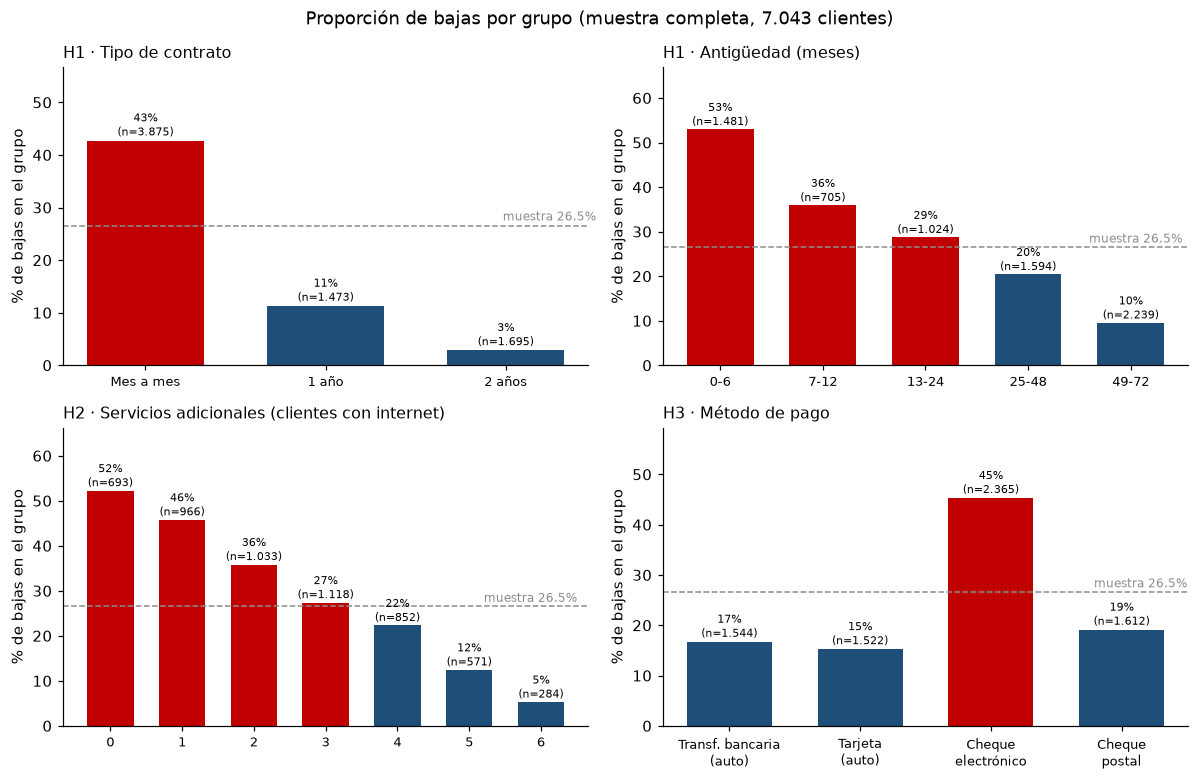

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2))
paneles = [
    (eda['h1_contrato'], 'H1 · Tipo de contrato', ['Mes a mes', '1 año', '2 años']),
    (eda['h1_antiguedad'], 'H1 · Antigüedad (meses)', None),
    (eda['h2_servicios_con_internet'], 'H2 · Servicios adicionales (clientes con internet)', None),
    (eda['h3_pago'], 'H3 · Método de pago', ['Transf. bancaria\n(auto)', 'Tarjeta\n(auto)', 'Cheque\nelectrónico', 'Cheque\npostal']),
]
for ax, (t, titulo, etiquetas) in zip(axes.ravel(), paneles):
    x = np.arange(len(t))
    colores = [ROJO if v > prevalencia else AZUL for v in t['tasa_churn']]
    ax.bar(x, t['tasa_churn'] * 100, color=colores, width=0.65)
    ax.axhline(prevalencia * 100, color=GRIS, ls='--', lw=1)
    ax.text(len(t) - 0.5, prevalencia * 100 + 1, f'muestra {prevalencia:.1%}', ha='right', fontsize=8, color=GRIS)
    for i, (v, n) in enumerate(zip(t['tasa_churn'], t['clientes'])):
        ax.text(i, v * 100 + 1, f'{v:.0%}\n(n={n:,})'.replace(',', '.'), ha='center', fontsize=7.5)
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas or [str(i) for i in t.index], fontsize=8.5)
    ax.set_ylim(0, max(t['tasa_churn']) * 100 + 14)
    ax.set_ylabel('% de bajas en el grupo')
    ax.set_title(titulo, fontsize=10.5, loc='left')
fig.suptitle('Proporción de bajas por grupo (muestra completa, 7.043 clientes)', fontsize=11.5)
fig.tight_layout()
fig.savefig(RESULTS / 'fig_eda.png', dpi=170, bbox_inches='tight')
plt.show()

## 3. Preparación de los datos

Decisiones (registradas en `data_log.md`):

| Decisión | Motivo |
|---|---|
| `TotalCharges` en blanco → 0 | Los 11 blancos son clientes con `tenure = 0`: todavía no fueron facturados. El archivo del curso los había imputado con la mediana (1.397,475), lo que es inconsistente con un cliente nuevo. |
| Sin tratamiento de outliers | El criterio IQR no detecta valores atípicos en `tenure`, `MonthlyCharges` ni `TotalCharges`; la cola de `TotalCharges` corresponde a clientes antiguos legítimos. |
| No agrupar categorías | El nivel menos frecuente tiene 682 clientes: no hay categorías raras. |
| Conservar los 22 perfiles repetidos | Tienen distinto `customerID`: son clientes distintos con el mismo perfil, no errores de carga. |
| `n_servicios_adicionales` | Resume H2 en una sola variable (0 a 6 servicios). |
| `pago_automatico` | Débito automático (banco o tarjeta) vs. pago manual. |
| `variacion_cargo` | `MonthlyCharges - TotalCharges / tenure`: diferencia entre el cargo actual y el promedio histórico (aproxima aumentos de precio). |
| One-hot + estandarización dentro de un `Pipeline` | Se ajustan solo con los datos de entrenamiento de cada fold: evita fuga entre particiones. |
| Sin ponderar clases | El objetivo es ordenar; la ponderación cambia la escala del score. Se verifica con evidencia en la sección 4. |

In [8]:
SERVICIOS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']


def preparar(datos):
    d = datos.copy()
    d['TotalCharges'] = pd.to_numeric(d['TotalCharges'].replace(r'^\s*$', np.nan, regex=True))
    d.loc[d['tenure'] == 0, 'TotalCharges'] = 0.0   # cliente nuevo: todavía no facturó
    d['n_servicios_adicionales'] = (d[SERVICIOS] == 'Yes').sum(axis=1)
    d['pago_automatico'] = d['PaymentMethod'].str.contains('automatic').astype(int)
    cargo_hist = np.where(d['tenure'] > 0, d['TotalCharges'] / d['tenure'].clip(lower=1), d['MonthlyCharges'])
    d['variacion_cargo'] = d['MonthlyCharges'] - cargo_hist
    return d


part = pd.read_csv(DATA_DIR / 'particion_curso.csv')
df = preparar(df_raw).merge(part, on='customerID', how='left', validate='one_to_one')
assert df['particion'].notna().all() and df['TotalCharges'].notna().all()

NUMERICAS = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicios_adicionales',
             'pago_automatico', 'variacion_cargo']
CATEGORICAS = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService'] + SERVICIOS + \
              ['Contract', 'PaperlessBilling', 'PaymentMethod']
FEATURES = NUMERICAS + CATEGORICAS

dev = df[df['particion'] == 'train'].sort_values('orden').reset_index(drop=True)
test = df[df['particion'] == 'test'].sort_values('orden').reset_index(drop=True)
X_dev, y_dev = dev[FEATURES], (dev['Churn'] == 'Yes').astype(int).values
X_test, y_test = test[FEATURES], (test['Churn'] == 'Yes').astype(int).values
print(f'Desarrollo: {len(dev):,} clientes ({y_dev.mean():.2%} bajas) | Test: {len(test):,} clientes ({y_test.mean():.2%} bajas, {y_test.sum()} casos)')


def preprocesador(cols):
    num = [c for c in cols if c in NUMERICAS]
    cat = [c for c in cols if c in CATEGORICAS]
    return ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
    ])


def armar(modelo, cols=FEATURES):
    return Pipeline([('prep', preprocesador(cols)), ('modelo', modelo)])

Desarrollo: 5,634 clientes (26.54% bajas) | Test: 1,409 clientes (26.54% bajas, 374 casos)


## 4. Modelado

### 4.1 Reproducción del baseline de la pre-entrega

La pre-entrega tomó como baseline una regresión logística del Módulo 5 (ROC-AUC 0,848 en validación y 0,845 en CV). Para documentar su reproducibilidad, la celda siguiente reconstruye **exactamente** el `train.csv` del curso desde la fuente oficial (mismos clientes, mismo orden y la misma imputación con la mediana que traía ese archivo) y corre la misma configuración:

`StandardScaler` + `OneHotEncoder(handle_unknown='ignore')` → `LogisticRegression(max_iter=1000, random_state=42)`, split 80/20 estratificado con `random_state=42` y CV de 5 folds sobre el 80 %.

In [9]:
curso = df_raw.merge(part[part['particion'] == 'train'], on='customerID').sort_values('orden')
curso = curso[COLUMNAS].reset_index(drop=True)
tc = pd.to_numeric(curso['TotalCharges'].replace(r'^\s*$', np.nan, regex=True))
curso['TotalCharges'] = tc.fillna(pd.to_numeric(df_raw['TotalCharges'], errors='coerce').median())  # como el archivo del curso

Xc = curso.drop(columns=['customerID', 'Churn'])
yc = (curso['Churn'] == 'Yes').astype(int)
cat_c = Xc.select_dtypes(include='object').columns.tolist()
num_c = Xc.select_dtypes(exclude='object').columns.tolist()
pipe_m5 = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), num_c),
                                ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_c)])),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
cv_m5 = cross_val_score(pipe_m5, Xc_tr, yc_tr, cv=5, scoring='roc_auc')
pipe_m5.fit(Xc_tr, yc_tr)
auc_m5 = roc_auc_score(yc_va, pipe_m5.predict_proba(Xc_va)[:, 1])
baseline_pre = pd.Series({'ROC_AUC_validacion': round(auc_m5, 4), 'ROC_AUC_CV5': round(cv_m5.mean(), 4),
                          'reportado_pre_entrega_validacion': 0.848, 'reportado_pre_entrega_CV5': 0.845})
baseline_pre.to_csv(RESULTS / 'baseline_preentrega.csv', header=['valor'])
print(baseline_pre)
assert abs(auc_m5 - 0.848) < 0.001 and abs(cv_m5.mean() - 0.845) < 0.001

ROC_AUC_validacion                  0.8481
ROC_AUC_CV5                         0.8452
reportado_pre_entrega_validacion    0.8480
reportado_pre_entrega_CV5           0.8450
dtype: float64


### 4.2 Validación cruzada y regla de selección ex ante

- **Holdout:** el `test.csv` del curso (1.409 clientes, 20 %) se usa una sola vez, después de elegir el modelo.
- **CV estratificada de 5 folds** sobre los 5.634 clientes de desarrollo para comparar algoritmos.
- **Algoritmos:** los tres del Módulo 5 (regresión logística, kNN, Naive Bayes) y los dos comprometidos en la pre-entrega (Random Forest y XGBoost). Configuraciones fijas, sin búsqueda de hiperparámetros sobre el test.

**Regla de selección (definida antes de correr la CV):**
1. Solo son elegibles los modelos con ROC-AUC media en CV ≥ 0,80 (umbral de la pre-entrega).
2. Entre los elegibles, se toma el de mayor Recall @ 20 % medio; los modelos a menos de un desvío estándar de ese valor se consideran **empatados**.
3. Si la regresión logística está entre los empatados, se elige la logística (más simple, interpretable y fácil de mantener). Si no, se elige el empatado con mayor PR-AUC media.

In [10]:
MODELOS = {
    'Regresión logística': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'kNN (k=15)': KNeighborsClassifier(n_neighbors=15),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(cv.split(X_dev, y_dev))


def evaluar_cv(pipe, X=X_dev, y=y_dev):
    filas = []
    for tr, va in FOLDS:
        m = clone(pipe)
        t0 = time.perf_counter()
        m.fit(X.iloc[tr], y[tr])
        seg = time.perf_counter() - t0
        s = m.predict_proba(X.iloc[va])[:, 1]
        filas.append({**metricas(y[va], s), 'Brier': brier_score_loss(y[va], s), 'seg_entrenamiento': seg})
    return pd.DataFrame(filas)


cv_detalle = {nombre: evaluar_cv(armar(m)) for nombre, m in MODELOS.items()}
cols_cv = ['PR_AUC', 'ROC_AUC', 'Recall@20', 'Precision@20', 'Lift@20', 'Brier', 'seg_entrenamiento']
cv_df = pd.DataFrame({n: {**{f'{c}_media': r[c].mean() for c in cols_cv}, **{f'{c}_desvio': r[c].std() for c in cols_cv}}
                      for n, r in cv_detalle.items()}).T
cv_df.round(4).to_csv(RESULTS / 'cv_5folds.csv')
pd.concat(cv_detalle, names=['modelo', 'fold']).round(4).to_csv(RESULTS / 'cv_folds_detalle.csv')

# Regla de selección ex ante
elegibles = cv_df[cv_df['ROC_AUC_media'] >= 0.80]
mejor = elegibles['Recall@20_media'].idxmax()
umbral_empate = elegibles.loc[mejor, 'Recall@20_media'] - elegibles.loc[mejor, 'Recall@20_desvio']
empatados = elegibles.index[elegibles['Recall@20_media'] >= umbral_empate].tolist()
CHOSEN = 'Regresión logística' if 'Regresión logística' in empatados else elegibles.loc[empatados, 'PR_AUC_media'].idxmax()

seleccion = pd.DataFrame({
    'ROC_AUC_CV': cv_df['ROC_AUC_media'].round(3),
    'elegible_ROC>=0,80': cv_df['ROC_AUC_media'] >= 0.80,
    'Recall@20_CV': cv_df['Recall@20_media'].round(3),
    'desvio': cv_df['Recall@20_desvio'].round(3),
    'empatado_con_el_mejor': cv_df.index.isin(empatados),
})
seleccion.to_csv(RESULTS / 'seleccion.csv')
print(f'Mejor Recall@20 en CV: {mejor} | umbral de empate: {umbral_empate:.3f} | empatados: {empatados}')
print('Modelo elegido por la regla:', CHOSEN)
cv_df[[c for c in cv_df.columns if c.endswith('_media')]].round(3)

Mejor Recall@20 en CV: XGBoost | umbral de empate: 0.486 | empatados: ['Regresión logística', 'Naive Bayes', 'Random Forest', 'XGBoost']
Modelo elegido por la regla: Regresión logística


,PR_AUC_media,ROC_AUC_media,Recall@20_media,Precision@20_media,Lift@20_media,Brier_media,seg_entrenamiento_media
Regresión logística,0.659,0.846,0.506,0.669,2.521,0.135,0.041
kNN (k=15),0.581,0.819,0.476,0.629,2.371,0.147,0.025
Naive Bayes,0.611,0.820,0.488,0.645,2.431,0.286,0.025
Random Forest,0.654,0.844,0.502,0.665,2.505,0.136,0.827
XGBoost,0.661,0.844,0.507,0.671,2.528,0.136,0.810


**Decisión pendiente de la pre-entrega: ¿balancear clases?** Se compara la logística con y sin `class_weight='balanced'` con los mismos folds. SMOTE no se evalúa: genera clientes sintéticos y, para un problema de ranking, no agrega nada que no haga la ponderación.

In [11]:
balanceo = pd.DataFrame({
    'Sin ponderar': cv_detalle['Regresión logística'].mean(),
    "class_weight='balanced'": evaluar_cv(armar(LogisticRegression(max_iter=1000, class_weight='balanced',
                                                                   random_state=RANDOM_STATE))).mean(),
}).T[['PR_AUC', 'ROC_AUC', 'Recall@20', 'Precision@20', 'Brier']].round(4)
balanceo.to_csv(RESULTS / 'chequeo_balanceo.csv')
balanceo

,PR_AUC,ROC_AUC,Recall@20,Precision@20,Brier
Sin ponderar,0.6591,0.8456,0.5057,0.6690,0.1353
class_weight='balanced',0.6580,0.8454,0.5030,0.6655,0.1655


## 5. Evaluación en el test (una sola vez)

Se comparan los modelos contra tres referencias:

- **Clase mayoritaria** (predecir siempre "no se va"): muestra que una accuracy alta puede ser inútil. Como asigna el mismo score a todos, no ordena y no tiene métricas @20.
- **Contacto aleatorio**: benchmark operativo de la pre-entrega (promedio de 500 órdenes al azar).
- **Regla de negocio**: benchmark de la pre-entrega ("contactar a los clientes mes a mes"). Como los contratos mes a mes son el 55 % de la cartera y el cupo es 20 %, dentro de ese grupo se prioriza a los de menor antigüedad.

In [12]:
fitted = {n: armar(m).fit(X_dev, y_dev) for n, m in MODELOS.items()}
scores = {n: p.predict_proba(X_test)[:, 1] for n, p in fitted.items()}

rng = np.random.default_rng(RANDOM_STATE)
score_regla = (X_test['Contract'] == 'Month-to-month') * 1000 + (72 - X_test['tenure']) + rng.random(len(X_test))
score_regla = score_regla.values

mayoritaria = pd.Series({'accuracy': accuracy_score(y_test, np.zeros_like(y_test)), 'PR_AUC': y_test.mean(), 'ROC_AUC': 0.5})
mayoritaria.round(4).to_csv(RESULTS / 'baseline_mayoritaria.csv', header=['valor'])

aleatorio = pd.DataFrame([metricas(y_test, rng.random(len(y_test))) for _ in range(500)]).mean()
filas = {'Contacto aleatorio': aleatorio, 'Regla de negocio (mes a mes + menor antigüedad)': pd.Series(metricas(y_test, score_regla))}
filas.update({n: pd.Series(metricas(y_test, s)) for n, s in scores.items()})
test_df = pd.DataFrame(filas).T
test_df.round(4).to_csv(RESULTS / 'model_metrics.csv')
print('Clase mayoritaria:', mayoritaria.round(3).to_dict())
test_df.round(3)

Clase mayoritaria: {'accuracy': 0.735, 'PR_AUC': 0.265, 'ROC_AUC': 0.5}


,PR_AUC,ROC_AUC,Recall@20,Precision@20,Lift@20,F1@20
Contacto aleatorio,0.269,0.499,0.200,0.265,0.999,0.228
Regla de negocio (mes a mes + menor antigüedad),0.539,0.791,0.447,0.592,2.231,0.509
Regresión logística,0.634,0.842,0.497,0.660,2.485,0.567
kNN (k=15),0.558,0.806,0.465,0.617,2.325,0.530
Naive Bayes,0.573,0.806,0.457,0.606,2.284,0.521
Random Forest,0.653,0.841,0.503,0.667,2.512,0.573
XGBoost,0.660,0.845,0.508,0.674,2.538,0.579


In [13]:
s_best = scores[CHOSEN]
top = top_k_mask(s_best)
cm = confusion_matrix(y_test, top.astype(int))
matriz = pd.DataFrame(cm, index=['Real: se queda', 'Real: se va'], columns=['No contactado', 'Contactado (top 20 %)'])
matriz.to_csv(RESULTS / 'matriz_confusion_top20.csv')
print(matriz, '\n')

# Ingreso mensual en riesgo capturado: cargo mensual de los que se van y quedan dentro del cupo
mc = X_test['MonthlyCharges'].values
ingreso = pd.Series({
    'clientes_contactados': int(top.sum()),
    'bajas_capturadas': int(cm[1, 1]),
    'bajas_totales_test': int(y_test.sum()),
    'ingreso_mensual_en_riesgo_total': mc[y_test == 1].sum(),
    'ingreso_mensual_en_riesgo_capturado': mc[(y_test == 1) & top].sum(),
})
ingreso['pct_ingreso_capturado'] = ingreso['ingreso_mensual_en_riesgo_capturado'] / ingreso['ingreso_mensual_en_riesgo_total']
ingreso.round(4).to_csv(RESULTS / 'ingreso_en_riesgo.csv', header=['valor'])
print(ingreso.round(3))

# Si cambia la capacidad del equipo: recall y precision para distintos cupos
cap = []
for k in [0.10, 0.20, 0.30, 0.40, 0.50]:
    for nombre, s in [(CHOSEN, s_best), ('Regla de negocio', score_regla)]:
        m = metricas(y_test, s, k)
        cap.append({'cupo': f'{k:.0%}', 'modelo': nombre, 'recall': m['Recall@20'], 'precision': m['Precision@20'], 'lift': m['Lift@20']})
capacidad = pd.DataFrame(cap).pivot(index='cupo', columns='modelo')
capacidad.round(3).to_csv(RESULTS / 'capacidad.csv')
capacidad.round(3)

                No contactado  Contactado (top 20 %)
Real: se queda            939                     96
Real: se va               188                    186 

clientes_contactados                     282.000
bajas_capturadas                         186.000
bajas_totales_test                       374.000
ingreso_mensual_en_riesgo_total        27214.900
ingreso_mensual_en_riesgo_capturado    14773.150
pct_ingreso_capturado                      0.543
dtype: float64


recall                            precision  \
modelo Regla de negocio Regresión logística Regla de negocio   
cupo                                                           
10%               0.246               0.283            0.652   
20%               0.447               0.497            0.592   
30%               0.602               0.650            0.532   
40%               0.717               0.778            0.475   
50%               0.845               0.872            0.448   

                                       lift                      
modelo Regresión logística Regla de negocio Regresión logística  
cupo                                                             
10%                  0.752            2.458               2.832  
20%                  0.660            2.231               2.485  
30%                  0.574            2.004               2.164  
40%                  0.516            1.790               1.944  
50%                  0.462            1.689               1.742

In [14]:
# Intervalos de confianza bootstrap (1.000 remuestreos del test)
rng_b = np.random.default_rng(RANDOM_STATE)
n = len(y_test)
reg = []
for _ in range(1000):
    i = rng_b.integers(0, n, n)
    mb, mr = metricas(y_test[i], s_best[i]), metricas(y_test[i], score_regla[i])
    mx = metricas(y_test[i], scores['XGBoost'][i])
    reg.append({'Recall@20_modelo': mb['Recall@20'], 'Recall@20_regla': mr['Recall@20'],
                'dif_Recall@20': mb['Recall@20'] - mr['Recall@20'],
                'Precision@20_modelo': mb['Precision@20'], 'PR_AUC_modelo': mb['PR_AUC'], 'ROC_AUC_modelo': mb['ROC_AUC'],
                'dif_Recall@20_XGB-elegido': mx['Recall@20'] - mb['Recall@20'], 'dif_PR_AUC_XGB-elegido': mx['PR_AUC'] - mb['PR_AUC']})
boot = pd.DataFrame(reg)
ic = boot.quantile([0.025, 0.975]).T.rename(columns={0.025: 'IC95_inf', 0.975: 'IC95_sup'})
ic.insert(0, 'estimacion_test', [test_df.loc[CHOSEN, 'Recall@20'], test_df.loc['Regla de negocio (mes a mes + menor antigüedad)', 'Recall@20'],
                                 test_df.loc[CHOSEN, 'Recall@20'] - test_df.loc['Regla de negocio (mes a mes + menor antigüedad)', 'Recall@20'],
                                 test_df.loc[CHOSEN, 'Precision@20'], test_df.loc[CHOSEN, 'PR_AUC'], test_df.loc[CHOSEN, 'ROC_AUC'],
                                 test_df.loc['XGBoost', 'Recall@20'] - test_df.loc[CHOSEN, 'Recall@20'],
                                 test_df.loc['XGBoost', 'PR_AUC'] - test_df.loc[CHOSEN, 'PR_AUC']])
ic['prob_dif_<=0'] = np.nan
for c in ['dif_Recall@20', 'dif_Recall@20_XGB-elegido', 'dif_PR_AUC_XGB-elegido']:
    ic.loc[c, 'prob_dif_<=0'] = (boot[c] <= 0).mean()
ic.round(4).to_csv(RESULTS / 'bootstrap_ic.csv')
ic.round(3)

,estimacion_test,IC95_inf,IC95_sup,prob_dif_<=0
Recall@20_modelo,0.497,0.462,0.547,NaN
Recall@20_regla,0.447,0.409,0.488,NaN
dif_Recall@20,0.051,0.010,0.102,0.010
Precision@20_modelo,0.660,0.606,0.720,NaN
PR_AUC_modelo,0.634,0.579,0.683,NaN
ROC_AUC_modelo,0.842,0.819,0.863,NaN
dif_Recall@20_XGB-elegido,0.011,-0.019,0.036,0.299
dif_PR_AUC_XGB-elegido,0.026,0.002,0.050,0.012


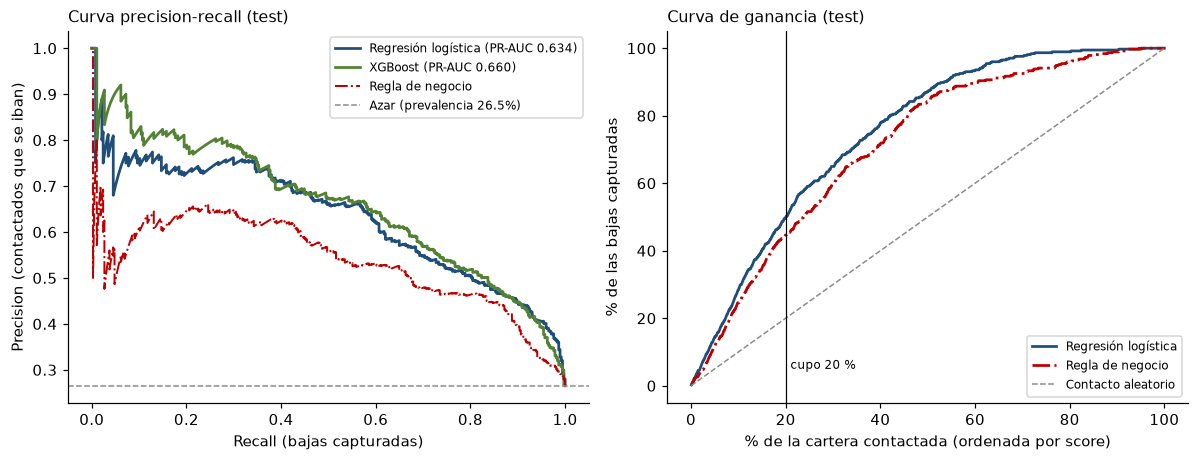

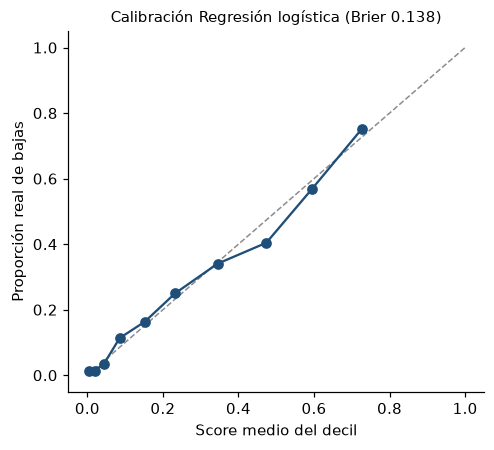

,clientes,bajas,tasa,lift,recall_acumulado
decil,,,,,
1,141,106,0.752,2.832,0.283
2,141,80,0.567,2.138,0.497
3,141,57,0.404,1.523,0.650
4,141,48,0.340,1.283,0.778
5,141,35,0.248,0.935,0.872
6,141,24,0.170,0.641,0.936
7,141,15,0.106,0.401,0.976
8,141,5,0.035,0.134,0.989
9,141,2,0.014,0.053,0.995


In [15]:
# Curvas precision-recall y de ganancia + lift por deciles + calibración
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
for nombre, color in [(CHOSEN, AZUL), ('XGBoost' if CHOSEN != 'XGBoost' else 'Random Forest', VERDE)]:
    p, r, _ = precision_recall_curve(y_test, scores[nombre])
    ax.plot(r, p, color=color, lw=1.8, label=f'{nombre} (PR-AUC {test_df.loc[nombre, "PR_AUC"]:.3f})')
p, r, _ = precision_recall_curve(y_test, score_regla)
ax.plot(r, p, color=ROJO, lw=1.3, ls='-.', label='Regla de negocio')
ax.axhline(y_test.mean(), color=GRIS, ls='--', lw=1, label=f'Azar (prevalencia {y_test.mean():.1%})')
ax.set_xlabel('Recall (bajas capturadas)')
ax.set_ylabel('Precision (contactados que se iban)')
ax.set_title('Curva precision-recall (test)', loc='left', fontsize=10.5)
ax.legend(fontsize=8)

ax = axes[1]
frac = np.arange(1, n + 1) / n
for nombre, s, color, ls in [(CHOSEN, s_best, AZUL, '-'), ('Regla de negocio', score_regla, ROJO, '-.')]:
    orden = np.argsort(-s, kind='mergesort')
    ax.plot(frac * 100, np.cumsum(y_test[orden]) / y_test.sum() * 100, color=color, lw=1.8, ls=ls, label=nombre)
ax.plot([0, 100], [0, 100], color=GRIS, ls='--', lw=1, label='Contacto aleatorio')
ax.axvline(K * 100, color='black', lw=0.8)
ax.text(K * 100 + 1, 5, 'cupo 20 %', fontsize=8)
ax.set_xlabel('% de la cartera contactada (ordenada por score)')
ax.set_ylabel('% de las bajas capturadas')
ax.set_title('Curva de ganancia (test)', loc='left', fontsize=10.5)
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(RESULTS / 'fig_pr_ganancia.png', dpi=170, bbox_inches='tight')
plt.show()

dec = pd.DataFrame({'y': y_test, 's': s_best}).sort_values('s', ascending=False, kind='mergesort').reset_index(drop=True)
dec['decil'] = np.arange(len(dec)) * 10 // len(dec) + 1
lift = dec.groupby('decil').agg(clientes=('y', 'size'), bajas=('y', 'sum'), tasa=('y', 'mean'))
lift['lift'] = lift['tasa'] / y_test.mean()
lift['recall_acumulado'] = lift['bajas'].cumsum() / y_test.sum()
lift.round(3).to_csv(RESULTS / 'lift_deciles.csv')

frac_pos, media_pred = calibration_curve(y_test, s_best, n_bins=10, strategy='quantile')
brier = brier_score_loss(y_test, s_best)
pd.DataFrame({'score_medio': media_pred, 'tasa_real': frac_pos}).round(4).to_csv(RESULTS / 'calibracion.csv', index=False)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1)
ax.plot(media_pred, frac_pos, marker='o', color=AZUL)
ax.set_xlabel('Score medio del decil')
ax.set_ylabel('Proporción real de bajas')
ax.set_title(f'Calibración {CHOSEN} (Brier {brier:.3f})', fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS / 'fig_calibracion.png', dpi=170, bbox_inches='tight')
plt.show()
lift.round(3)

## 6. Validación temporal

El modelo de referencia de la cátedra evalúa además en un período posterior. **Con estos datos no es posible**: el archivo no tiene fechas ni orden cronológico, es una única foto de la cartera. Por eso:

- no se puede medir si el modelo se degrada con el tiempo (drift);
- la robustez se acota con el desvío entre folds y los intervalos bootstrap del test;
- para un uso real, el diseño correcto es calcular las variables a una fecha de corte *t* y observar las bajas en una ventana posterior (por ejemplo, 30 o 90 días), y validar entrenando con cortes anteriores y evaluando en cortes posteriores. Es el primer paso del plan de implementación (sección 6 del informe).

## 7. Interpretabilidad con SHAP

Se explica el modelo elegido sobre el test. Las columnas one-hot se suman por variable original para que negocio lea "Contract" y no tres columnas. En la regresión logística los valores SHAP están en **log-odds**: el signo indica dirección y la magnitud cuánto mueve el score. SHAP describe cómo razona el modelo; **no prueba causalidad**.

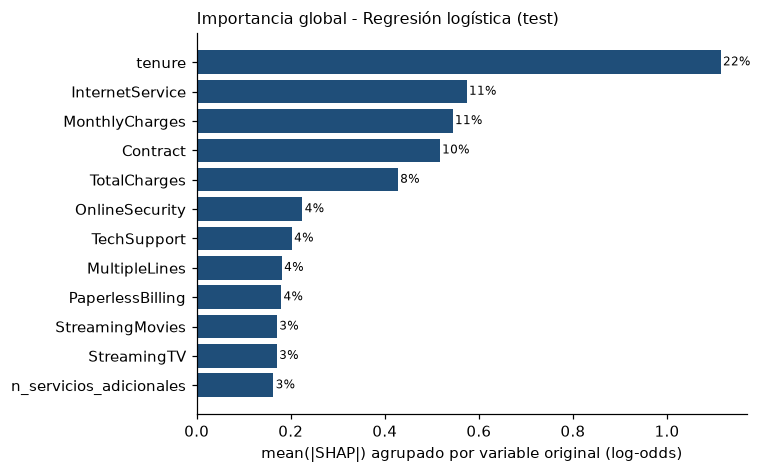

Valor base (log-odds): -1.703


,mean_abs_shap,pct
tenure,1.114,0.220
InternetService,0.574,0.114
MonthlyCharges,0.544,0.108
Contract,0.517,0.102
TotalCharges,0.428,0.085
OnlineSecurity,0.225,0.044
TechSupport,0.202,0.040
MultipleLines,0.181,0.036
PaperlessBilling,0.180,0.036
StreamingMovies,0.171,0.034


In [16]:
pipe = fitted[CHOSEN]
pre, modelo = pipe.named_steps['prep'], pipe.named_steps['modelo']
nombres = pre.get_feature_names_out()
Xt_dev, Xt_test = pre.transform(X_dev), pre.transform(X_test)


def var_original(f):
    tipo, resto = f.split('__', 1)
    if tipo == 'num':
        return resto
    return next(c for c in sorted(CATEGORICAS, key=len, reverse=True) if resto.startswith(c + '_'))


if isinstance(modelo, LogisticRegression):
    explainer = shap.LinearExplainer(modelo, shap.maskers.Independent(Xt_dev, max_samples=Xt_dev.shape[0]))
    sv = explainer.shap_values(Xt_test)
    base = float(np.ravel(explainer.expected_value)[0])
    margen = modelo.decision_function(Xt_test)
    escala = 'log-odds'
else:
    explainer = shap.TreeExplainer(modelo)
    sv = explainer.shap_values(Xt_test)
    if isinstance(sv, list) or np.ndim(sv) == 3:
        sv = sv[1] if isinstance(sv, list) else sv[:, :, 1]
        base = float(np.ravel(explainer.expected_value)[-1])
        margen = modelo.predict_proba(Xt_test)[:, 1]
        escala = 'probabilidad'
    else:
        base = float(np.ravel(explainer.expected_value)[0])
        margen = modelo.predict(Xt_test, output_margin=True)
        escala = 'log-odds'
assert np.allclose(base + sv.sum(axis=1), margen, atol=1e-4), 'SHAP no reconstruye el output del modelo'

sv_grp = pd.DataFrame(sv, columns=nombres).T.groupby(var_original).sum().T
imp = sv_grp.abs().mean().sort_values(ascending=False).rename('mean_abs_shap').to_frame()
imp['pct'] = imp['mean_abs_shap'] / imp['mean_abs_shap'].sum()
imp.round(4).to_csv(RESULTS / 'shap_global.csv')

top_n = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(top_n.index, top_n['mean_abs_shap'], color=AZUL)
for i, (v, p) in enumerate(zip(top_n['mean_abs_shap'], top_n['pct'])):
    ax.text(v + 0.005, i, f'{p:.0%}', va='center', fontsize=8)
ax.set_xlabel(f'mean(|SHAP|) agrupado por variable original ({escala})')
ax.set_title(f'Importancia global - {CHOSEN} (test)', loc='left', fontsize=10.5)
fig.tight_layout()
fig.savefig(RESULTS / 'fig_shap_global.png', dpi=170, bbox_inches='tight')
plt.show()

if isinstance(modelo, LogisticRegression):
    coef = pd.DataFrame({'variable': nombres, 'coeficiente': modelo.coef_[0]})
    coef['odds_ratio'] = np.exp(coef['coeficiente'])
    coef.sort_values('coeficiente', ascending=False).round(4).to_csv(RESULTS / 'coeficientes_logistica.csv', index=False)
print(f'Valor base ({escala}): {base:.3f}')
imp.round(3)

In [17]:
# Dirección del efecto: SHAP medio por nivel de las variables categóricas más importantes
direccion = []
for var in imp.index[:8]:
    if var in CATEGORICAS:
        for nivel, g in pd.Series(sv_grp[var].values, index=X_test[var].values).groupby(level=0):
            direccion.append({'variable': var, 'valor': nivel, 'shap_medio': g.mean(), 'clientes': len(g)})
    else:
        r = np.corrcoef(X_test[var].values, sv_grp[var].values)[0, 1]
        efecto = 'a mayor valor, sube el score' if r > 0 else 'a mayor valor, baja el score'
        direccion.append({'variable': var, 'valor': efecto, 'shap_medio': np.nan, 'clientes': len(X_test)})
direccion = pd.DataFrame(direccion)
direccion.round(3).to_csv(RESULTS / 'shap_direccion.csv', index=False)

# Lectura por bloques: tenure, TotalCharges y MonthlyCharges están mecánicamente relacionadas entre sí y con los
# servicios contratados, así que sus contribuciones individuales se compensan. Sumarlas por bloque da una lectura más estable.
BLOQUE_DE = {**{v: 'H1 Contrato y antigüedad' for v in ['Contract', 'tenure', 'TotalCharges', 'variacion_cargo']},
             **{v: 'H2 Servicios adicionales' for v in SERVICIOS + ['n_servicios_adicionales']},
             **{v: 'H3 Tipo de internet, cargo y pago' for v in ['InternetService', 'MonthlyCharges', 'PaymentMethod', 'PaperlessBilling', 'pago_automatico']},
             **{v: 'H4 Demográficas' for v in ['gender', 'SeniorCitizen', 'Partner', 'Dependents']},
             **{v: 'Telefonía' for v in ['PhoneService', 'MultipleLines']}}
sv_bloque = sv_grp.T.groupby(lambda v: BLOQUE_DE[v]).sum().T
shap_bloques = sv_bloque.abs().mean().sort_values(ascending=False).rename('mean_abs_shap').to_frame()
shap_bloques['pct'] = shap_bloques['mean_abs_shap'] / shap_bloques['mean_abs_shap'].sum()
shap_bloques.round(4).to_csv(RESULTS / 'shap_bloques.csv')
display(direccion.round(3))
shap_bloques.round(3)

,variable,valor,shap_medio,clientes
0,tenure,"a mayor valor, baja el score",NaN,1409
1,InternetService,DSL,-0.670,484
2,InternetService,Fiber optic,0.654,613
3,InternetService,No,-0.268,312
4,MonthlyCharges,"a mayor valor, baja el score",NaN,1409
5,Contract,Month-to-month,0.471,773
6,Contract,One year,-0.223,300
7,Contract,Two year,-0.884,336
8,TotalCharges,"a mayor valor, sube el score",NaN,1409
9,OnlineSecurity,No,0.226,701


,mean_abs_shap,pct
H1 Contrato y antigüedad,1.159,0.441
H2 Servicios adicionales,0.709,0.270
"H3 Tipo de internet, cargo y pago",0.484,0.184
Telefonía,0.180,0.068
H4 Demográficas,0.099,0.038


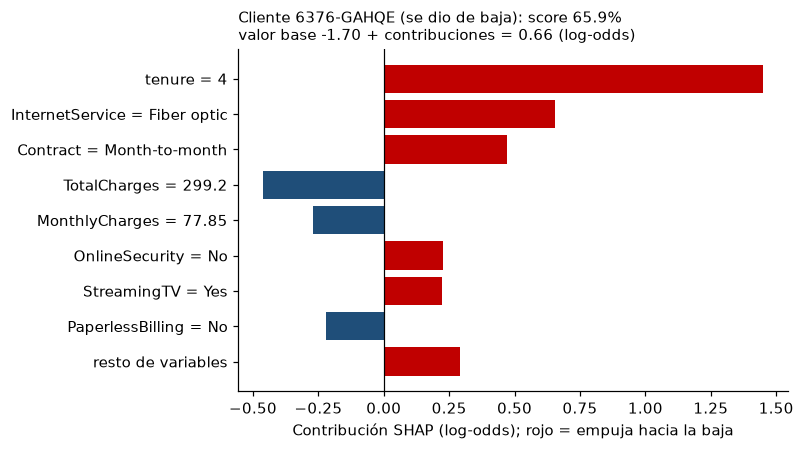

Cliente: 6376-GAHQE | base + suma SHAP = 0.6566 (log-odds) | score = 0.6585


,variable,valor_cliente,contribucion
0,tenure,4,1.448
1,InternetService,Fiber optic,0.654
2,Contract,Month-to-month,0.471
3,TotalCharges,299.2,-0.461
4,MonthlyCharges,77.85,-0.272
5,OnlineSecurity,No,0.226
6,StreamingTV,Yes,0.222
7,PaperlessBilling,No,-0.220
8,resto de variables,,0.292


In [18]:
# Caso local: un cliente real que se fue, dentro del top 20 %, con score cercano a la mediana de ese grupo
cand = np.where(top & (y_test == 1))[0]
idx = cand[np.argmin(np.abs(s_best[cand] - np.median(s_best[top])))]
contrib = sv_grp.iloc[idx].sort_values(key=np.abs, ascending=False)
principales = contrib.head(8)
resto = contrib.iloc[8:].sum()

local = pd.DataFrame({'variable': principales.index,
                      'valor_cliente': [str(X_test.iloc[idx][v]) for v in principales.index],
                      'contribucion': principales.values})
local.loc[len(local)] = ['resto de variables', '', resto]
local.round(4).to_csv(RESULTS / 'shap_local_case.csv', index=False)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
etiquetas = [f'{v} = {x}' if x else v for v, x in zip(local['variable'], local['valor_cliente'])][::-1]
vals = local['contribucion'].values[::-1]
ax.barh(etiquetas, vals, color=[ROJO if v > 0 else AZUL for v in vals])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel(f'Contribución SHAP ({escala}); rojo = empuja hacia la baja')
titulo_local = (f'Cliente {test.loc[idx, "customerID"]} (se dio de baja): score {s_best[idx]:.1%}' + chr(10) +
                f'valor base {base:.2f} + contribuciones = {base + sv[idx].sum():.2f} ({escala})')
ax.set_title(titulo_local, loc='left', fontsize=9.5)
fig.tight_layout()
fig.savefig(RESULTS / 'fig_shap_local.png', dpi=170, bbox_inches='tight')
plt.show()
print('Cliente:', test.loc[idx, 'customerID'], f'| base + suma SHAP = {base + sv[idx].sum():.4f} ({escala}) | score = {s_best[idx]:.4f}')
local.round(3)

## 8. Profundización

### 8.1 Ablaciones de hipótesis

Se reentrena el modelo elegido **sin** un bloque de variables y se mide la caída con los mismos 5 folds de desarrollo (no se usa el test para no reutilizarlo en decisiones). Como hay variables correlacionadas entre bloques, la caída es un piso del aporte de cada bloque.

In [19]:
BLOQUES = {
    'H1 - sin contrato ni antigüedad': ['Contract', 'tenure', 'TotalCharges', 'variacion_cargo'],
    'H2 - sin servicios adicionales': SERVICIOS + ['n_servicios_adicionales'],
    'H3 - sin tipo de internet ni pago': ['InternetService', 'PaymentMethod', 'PaperlessBilling', 'pago_automatico', 'MonthlyCharges'],
    'H4 - sin demográficas': ['gender', 'SeniorCitizen', 'Partner', 'Dependents'],
}
ref = cv_detalle[CHOSEN][['PR_AUC', 'Recall@20', 'ROC_AUC']].mean()
abl = [{'escenario': 'Modelo completo', 'PR_AUC': ref['PR_AUC'], 'Recall@20': ref['Recall@20'], 'ROC_AUC': ref['ROC_AUC']}]
for nombre, quitar in BLOQUES.items():
    cols = [c for c in FEATURES if c not in quitar]
    r = evaluar_cv(armar(clone(MODELOS[CHOSEN]), cols), X_dev[cols])[['PR_AUC', 'Recall@20', 'ROC_AUC']].mean()
    abl.append({'escenario': nombre, **r.to_dict()})
ablaciones = pd.DataFrame(abl).set_index('escenario')
ablaciones['delta_PR_AUC_pp'] = (ablaciones['PR_AUC'] - ref['PR_AUC']) * 100
ablaciones['delta_Recall@20_pp'] = (ablaciones['Recall@20'] - ref['Recall@20']) * 100
ablaciones.round(4).to_csv(RESULTS / 'ablaciones.csv')
ablaciones.round(3)

,PR_AUC,Recall@20,ROC_AUC,delta_PR_AUC_pp,delta_Recall@20_pp
escenario,,,,,
Modelo completo,0.659,0.506,0.846,0.000,0.000
H1 - sin contrato ni antigüedad,0.586,0.467,0.809,-7.343,-3.880
H2 - sin servicios adicionales,0.651,0.504,0.842,-0.793,-0.134
H3 - sin tipo de internet ni pago,0.639,0.490,0.837,-2.011,-1.538
H4 - sin demográficas,0.658,0.508,0.846,-0.128,0.201


### 8.2 Auditoría por grupos y modelo sin atributos sensibles

Se audita a quién selecciona el ranking según género, edad (adulto mayor), pareja e hijos a cargo: participación en la cartera, tasa de selección, proporción real de bajas y recall dentro de cada grupo. **Una diferencia de prevalencia entre grupos no demuestra ausencia de sesgo ni justifica automáticamente un trato diferencial**: si la retención implica descuentos, decidir quién los recibe tiene consecuencias.

También se entrena el mismo modelo **sin** esas cuatro variables para ver cuánto rendimiento se pierde y si la selección cambia (si existen variables proxy, quitar el atributo no elimina por sí solo la diferencia).

In [20]:
SENSIBLES = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
cols_ns = [c for c in FEATURES if c not in SENSIBLES]
pipe_ns = armar(clone(MODELOS[CHOSEN]), cols_ns).fit(X_dev[cols_ns], y_dev)
s_ns = pipe_ns.predict_proba(X_test[cols_ns])[:, 1]
top_ns = top_k_mask(s_ns)
sin_sens = pd.DataFrame({CHOSEN: metricas(y_test, s_best), f'{CHOSEN} sin atributos sensibles': metricas(y_test, s_ns)}).T
sin_sens.round(4).to_csv(RESULTS / 'modelo_sin_sensibles.csv')


def auditoria(seleccion, etiqueta):
    filas = []
    for var in SENSIBLES:
        valores = X_test[var].map({0: 'No', 1: 'Sí'}) if var == 'SeniorCitizen' else X_test[var]
        for g in sorted(valores.unique()):
            m = (valores == g).values
            filas.append({'modelo': etiqueta, 'atributo': var, 'grupo': g, 'clientes': int(m.sum()),
                          'pct_cartera': m.mean(), 'tasa_real_bajas': y_test[m].mean(),
                          'tasa_seleccion': seleccion[m].mean(), 'pct_del_top': seleccion[m].sum() / seleccion.sum(),
                          'recall_grupo': (seleccion[m] & (y_test[m] == 1)).sum() / max(1, y_test[m].sum()),
                          'precision_grupo': y_test[m][seleccion[m]].mean() if seleccion[m].any() else np.nan})
    return pd.DataFrame(filas)


audit = pd.concat([auditoria(top, CHOSEN), auditoria(top_ns, 'Sin atributos sensibles')], ignore_index=True)
audit.round(4).to_csv(RESULTS / 'auditoria_grupos.csv', index=False)
print(sin_sens.round(3), '\n')
audit.round(3)

                                             PR_AUC  ROC_AUC  Recall@20  \
Regresión logística                           0.634    0.842      0.497   
Regresión logística sin atributos sensibles   0.634    0.841      0.492   

                                             Precision@20  Lift@20  F1@20  
Regresión logística                                 0.660    2.485  0.567  
Regresión logística sin atributos sensibles         0.652    2.458  0.561   



,modelo,atributo,grupo,clientes,pct_cartera,tasa_real_bajas,tasa_seleccion,pct_del_top,recall_grupo,precision_grupo
0,Regresión logística,gender,Female,687,0.488,0.281,0.198,0.482,0.477,0.676
1,Regresión logística,gender,Male,722,0.512,0.251,0.202,0.518,0.519,0.644
2,Regresión logística,SeniorCitizen,No,1187,0.842,0.233,0.167,0.702,0.467,0.652
3,Regresión logística,SeniorCitizen,Sí,222,0.158,0.441,0.378,0.298,0.582,0.679
4,Regresión logística,Partner,No,736,0.522,0.337,0.285,0.745,0.552,0.652
5,Regresión logística,Partner,Yes,673,0.478,0.187,0.107,0.255,0.389,0.681
6,Regresión logística,Dependents,No,978,0.694,0.310,0.260,0.901,0.551,0.657
7,Regresión logística,Dependents,Yes,431,0.306,0.165,0.065,0.099,0.268,0.679
8,Sin atributos sensibles,gender,Female,687,0.488,0.281,0.199,0.486,0.472,0.664
9,Sin atributos sensibles,gender,Male,722,0.512,0.251,0.201,0.514,0.514,0.641


## 9. Traducción a negocio: escenario económico (paramétrico)

**Supuestos (no son costos reales de ninguna empresa):**
- costo promedio por cliente contactado (llamada, gestión e incentivo): **USD 15**;
- proporción de clientes que se iban a ir y, al ser contactados, se retienen: **25 %**;
- un cliente retenido aporta su cargo mensual durante **12 meses**.

El cálculo se hace **por campaña sobre una cartera con la composición del test** (1.409 clientes, 26,5 % de bajas) y se expresa también cada 1.000 clientes. No se interpreta como valor mensual ni anual de la empresa: el beneficio real depende de la proporción de bajas en la cartera activa durante la ventana de la campaña, que debe medirse en un piloto con grupo de control.

Lógica: `beneficio = tasa_retención × 12 × (cargo mensual de las bajas capturadas) − costo × contactados`.

In [21]:
COSTO, TASA_RET, MESES = 15.0, 0.25, 12
n_contact = int(top.sum())
mc_bajas = mc[y_test == 1].sum()


def escenario(nombre, ingreso_capt, tasa=TASA_RET, costo=COSTO):
    valor = tasa * MESES * ingreso_capt
    costo_total = costo * n_contact
    return {'estrategia': nombre, 'contactados': n_contact, 'ingreso_mensual_capturado': ingreso_capt,
            'valor_retenido': valor, 'costo_campania': costo_total, 'beneficio_neto': valor - costo_total,
            'beneficio_neto_cada_1000': (valor - costo_total) * 1000 / n}


capt = {
    'Contacto aleatorio (esperado)': K * mc_bajas,
    'Regla de negocio': mc[(y_test == 1) & top_k_mask(score_regla)].sum(),
    CHOSEN: mc[(y_test == 1) & top].sum(),
    f'{CHOSEN} sin atributos sensibles': mc[(y_test == 1) & top_ns].sum(),
}
eco = pd.DataFrame([escenario(k_, v) for k_, v in capt.items()]).set_index('estrategia')
eco['vs_aleatorio'] = eco['beneficio_neto'] - eco.loc['Contacto aleatorio (esperado)', 'beneficio_neto']
eco['pct_ingreso_en_riesgo_capturado'] = eco['ingreso_mensual_capturado'] / mc_bajas
eco.round(3).to_csv(RESULTS / 'escenario_economico.csv')

sens = []
for tasa in [0.10, 0.25, 0.40]:
    for costo in [10.0, 15.0, 25.0]:
        b_m = escenario(CHOSEN, capt[CHOSEN], tasa, costo)['beneficio_neto']
        b_a = escenario('a', capt['Contacto aleatorio (esperado)'], tasa, costo)['beneficio_neto']
        b_r = escenario('r', capt['Regla de negocio'], tasa, costo)['beneficio_neto']
        sens.append({'tasa_retencion': tasa, 'costo_contacto': costo, 'neto_modelo': b_m,
                     'neto_regla': b_r, 'neto_aleatorio': b_a, 'modelo_vs_aleatorio': b_m - b_a})
sensibilidad = pd.DataFrame(sens)
sensibilidad.round({'neto_modelo': 1, 'neto_regla': 1, 'neto_aleatorio': 1, 'modelo_vs_aleatorio': 1}).to_csv(RESULTS / 'sensibilidad_economica.csv', index=False)
equilibrio = COSTO * n_contact / (MESES * capt[CHOSEN])
print(f'Tasa de retención mínima para que el modelo no pierda plata (costo USD {COSTO:.0f}): {equilibrio:.1%}')
eco.round(0)

Tasa de retención mínima para que el modelo no pierda plata (costo USD 15): 2.4%


,contactados,ingreso_mensual_capturado,valor_retenido,costo_campania,beneficio_neto,beneficio_neto_cada_1000,vs_aleatorio,pct_ingreso_en_riesgo_capturado
estrategia,,,,,,,,
Contacto aleatorio (esperado),282,5443.0,16329.0,4230.0,12099.0,8587.0,0.0,0.0
Regla de negocio,282,10407.0,31221.0,4230.0,26991.0,19156.0,14892.0,0.0
Regresión logística,282,14773.0,44319.0,4230.0,40089.0,28452.0,27991.0,1.0
Regresión logística sin atributos sensibles,282,14792.0,44377.0,4230.0,40147.0,28493.0,28048.0,1.0


## 10. Resumen de resultados

In [22]:
resumen = {
    'modelo_elegido': CHOSEN,
    'empatados_en_cv': ', '.join(empatados),
    'cv_ROC_AUC': round(cv_df.loc[CHOSEN, 'ROC_AUC_media'], 4),
    'cv_PR_AUC': round(cv_df.loc[CHOSEN, 'PR_AUC_media'], 4),
    'cv_Recall@20': round(cv_df.loc[CHOSEN, 'Recall@20_media'], 4),
    'test_ROC_AUC': round(test_df.loc[CHOSEN, 'ROC_AUC'], 4),
    'test_PR_AUC': round(test_df.loc[CHOSEN, 'PR_AUC'], 4),
    'test_Recall@20': round(test_df.loc[CHOSEN, 'Recall@20'], 4),
    'test_Recall@20_IC95': f"{ic.loc['Recall@20_modelo', 'IC95_inf']:.3f} - {ic.loc['Recall@20_modelo', 'IC95_sup']:.3f}",
    'test_Precision@20': round(test_df.loc[CHOSEN, 'Precision@20'], 4),
    'test_Lift@20': round(test_df.loc[CHOSEN, 'Lift@20'], 3),
    'regla_Recall@20': round(test_df.loc['Regla de negocio (mes a mes + menor antigüedad)', 'Recall@20'], 4),
    'aleatorio_Recall@20': round(test_df.loc['Contacto aleatorio', 'Recall@20'], 4),
    'pct_ingreso_en_riesgo_capturado': round(ingreso['pct_ingreso_capturado'], 4),
    'brier_test': round(brier, 4),
    'meta_recall@20>=40%': bool(test_df.loc[CHOSEN, 'Recall@20'] >= 0.40),
    'meta_ROC_AUC>=0,80': bool(test_df.loc[CHOSEN, 'ROC_AUC'] >= 0.80),
    'beneficio_neto_modelo_cada_1000': round(eco.loc[CHOSEN, 'beneficio_neto_cada_1000'], 0),
    'beneficio_vs_aleatorio_cada_1000': round(eco.loc[CHOSEN, 'vs_aleatorio'] * 1000 / n, 0),
    'tasa_retencion_equilibrio': round(equilibrio, 4),
}
pd.Series(resumen).to_csv(RESULTS / 'resumen.csv', header=['valor'])
pd.Series(resumen)

modelo_elegido                                                    Regresión logística
empatados_en_cv                     Regresión logística, Naive Bayes, Random Fores...
cv_ROC_AUC                                                                     0.8456
cv_PR_AUC                                                                      0.6591
cv_Recall@20                                                                   0.5057
test_ROC_AUC                                                                    0.842
test_PR_AUC                                                                    0.6338
test_Recall@20                                                                 0.4973
test_Recall@20_IC95                                                     0.462 - 0.547
test_Precision@20                                                              0.6596
test_Lift@20                                                                    2.485
regla_Recall@20                                       

**Conclusión metodológica.** La regresión logística, elegida por la regla ex ante entre cuatro modelos empatados en CV, captura el 49,7 % de las bajas contactando al 20 % de la cartera (IC95 % bootstrap: 46,2 %-54,7 %), con una precisión del 66 % y lift 2,5: cumple las dos metas fijadas en la pre-entrega (Recall @ 20 % ≥ 40 % y ROC-AUC ≥ 0,80). Supera a la regla de negocio por 5,1 p.p. de recall (IC95 %: 1,0-10,2 p.p.) y, sobre todo, en ingreso mensual en riesgo capturado (54 % contra 38 %). XGBoost logra una PR-AUC algo mayor en el test, pero la diferencia en el KPI de negocio no es significativa y no cambia la regla definida antes de evaluar. Quitar los atributos sensibles casi no afecta el desempeño. Como el dataset no tiene dimensión temporal, el siguiente paso obligatorio es validar con cortes temporales y un piloto con grupo de control antes de cualquier despliegue.